# steps in k mean algorithumns

1. dataset
2. choose k
3. initializze centroid
4. calculate distances
5. assign nearest cluster
6. recalculate centroide
7. centroid changes
-----

# K-Means Clustering

## 1. What is it?
**K-Means** is an **unsupervised learning** algorithm that partitions data into **K clusters**, where each point belongs to the cluster with the **nearest centroid (mean)**.

- Input: data points and a chosen K
- Output: K cluster assignments and K centroids
- It is **centroid-based**, **hard clustering** (each point belongs to exactly one cluster)

---

## 2. Intuition
Imagine placing K flags on a map. Every house joins the nearest flag. Then each flag moves to the center of its houses. Repeat until the flags stop moving.

---

## 3. Objective Function

K-Means minimizes **WCSS (inertia)**:

$$
J = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2
$$

Where:
- $C_k$ = cluster k
- $\mu_k$ = centroid of cluster k, $\mu_k = \dfrac{1}{|C_k|} \sum_{x_i \in C_k} x_i$

---

## 4. Algorithm (Lloyd's Algorithm)
1. **Choose K.**
2. **Initialize** K centroids (random points or k-means++).
3. **Assignment step:** assign each point to its nearest centroid.

$$
c_i = \arg\min_k \lVert x_i - \mu_k \rVert^2
$$

4. **Update step:** recompute each centroid as the mean of its assigned points.
5. **Repeat** steps 3 and 4 until:
   - assignments stop changing, or
   - centroids move less than a tolerance, or
   - max iterations reached.

> This is an instance of **Expectation-Maximization** style optimization: step 3 is like E, step 4 is like M.

---

## 5. Visual Idea

```
Iteration 0        Iteration 1        Converged
 .  .   x           . . .  x            ooo   x
  . .  .             .o.   .            ooo    xxx
 x     . .          x    x  .           
 (random centroids) (assign+move)       (stable clusters)
```

Centroids drift toward the true cluster centers with each iteration.

---

## 6. Initialization: k-means++
Random initialization can give bad local minima. **k-means++** spreads out initial centroids:
1. Pick the first centroid randomly.
2. For each remaining centroid, pick a point with probability proportional to $D(x)^2$, where $D(x)$ is the distance to the nearest already chosen centroid.

Result: faster convergence and better final clusters. It is the **default in scikit-learn**.

---

## 7. Python Example

```python
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler

# Data
X, _ = make_blobs(n_samples=500, centers=4, random_state=42)
X = StandardScaler().fit_transform(X)

# Model
kmeans = KMeans(n_clusters=4, init='k-means++', n_init=10,
                max_iter=300, random_state=42)
labels = kmeans.fit_predict(X)

print("Centroids:\n", kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

# Plot
plt.scatter(X[:, 0], X[:, 1], c=labels, s=20)
plt.scatter(*kmeans.cluster_centers_.T, c='red', marker='X', s=200)
plt.title('K-Means Clustering (K=4)')
plt.show()
```

**Predict new points:**
```python
kmeans.predict([[0.5, -1.2]])
```

---

## 8. Key Hyperparameters (scikit-learn)

| Parameter | Meaning |
|---|---|
| `n_clusters` | Number of clusters K |
| `init` | `'k-means++'` (default) or `'random'` |
| `n_init` | Number of runs with different initializations; best is kept |
| `max_iter` | Maximum iterations per run |
| `tol` | Convergence tolerance |
| `random_state` | Reproducibility |

---

## 9. Choosing K
- **Elbow Method** (WCSS vs K)
- **Silhouette Score**
- **Gap Statistic**
- **Domain knowledge** (e.g., 3 customer segments needed by business)

---

## 10. Complexity
- **Time:** $O(n \cdot K \cdot d \cdot I)$
  - n = points, K = clusters, d = features, I = iterations
- **Space:** $O((n + K) \cdot d)$
- Scales well to large datasets; guaranteed to **converge**, but only to a **local minimum**.

---

## 11. Advantages
- Simple and easy to implement
- Fast and scalable to large datasets
- Works well with compact, spherical clusters
- Easy to interpret (centroids are meaningful)
- Can be retrained or extended (Mini-Batch K-Means for huge data)

## 12. Limitations
- Must **specify K** in advance
- Sensitive to **initialization** (local minima)
- Sensitive to **outliers** (mean gets pulled)
- Assumes **spherical, similar-sized, similar-density** clusters
- Struggles with **non-convex shapes** (moons, rings)
- Needs **feature scaling**
- Only for **numeric** data (Euclidean distance)
- Hard assignment only, no probabilities

---

## 13. Variants

| Variant | Idea |
|---|---|
| **K-Means++** | Smarter initialization |
| **Mini-Batch K-Means** | Uses small random batches; much faster for large data |
| **K-Medoids (PAM)** | Uses actual data points as centers; robust to outliers |
| **K-Modes** | For categorical data |
| **K-Prototypes** | Mixed numeric and categorical data |
| **Fuzzy C-Means** | Soft assignment (membership degrees) |
| **Gaussian Mixture Model** | Soft clustering, elliptical clusters |

---

## 14. K-Means vs Other Clustering

| Aspect | K-Means | Hierarchical | DBSCAN |
|---|---|---|---|
| Need K? | Yes | No (cut dendrogram) | No (needs eps, minPts) |
| Cluster shape | Spherical | Flexible | Arbitrary |
| Handles outliers | Poor | Moderate | Good (labels noise) |
| Scalability | High | Low | Moderate |
| Deterministic | No (init-dependent) | Yes | Mostly |

---

## 15. Applications
- Customer segmentation
- Image compression (color quantization)
- Document/topic grouping
- Anomaly detection (far from centroids)
- Feature engineering (cluster labels as features)
- Initializing other models (e.g., GMM)

---

## 16. Common Pitfalls
- **Not scaling features** (large-scale features dominate distance)
- Using K-Means on **categorical data**
- Trusting a **single run**; use higher `n_init`
- Ignoring **outliers**
- Picking K only from the elbow; validate with silhouette
- Applying to **non-spherical clusters**

---

## 17. Quick Revision Points
- **Type:** unsupervised, centroid-based, hard clustering
- **Goal:** minimize WCSS
- **Steps:** initialize → assign → update → repeat
- **Distance:** Euclidean
- **Converges** to a local minimum, not global
- **Init:** use k-means++
- **Choose K:** Elbow, Silhouette, Gap Statistic
- **Always scale** data first

---

## 18. Likely Exam / Interview Questions
1. **Does K-Means always converge?**
   Yes, WCSS never increases each iteration and there are finitely many partitions, but it may reach a local minimum.
2. **Why is K-Means sensitive to outliers?**
   Centroids are means, which get pulled toward extreme values.
3. **How does k-means++ help?**
   It spreads initial centroids apart, reducing bad local minima.
4. **Why does K-Means fail on moon-shaped data?**
   It assumes convex, spherical clusters based on distance to a center.
5. **K-Means vs K-Medoids?**
   K-Medoids uses actual data points as centers, so it is more robust to outliers.
6. **Is K-Means supervised?**
   No, it needs no labels.
7. **Time complexity?**
   $O(n \cdot K \cdot d \cdot I)$.

---

Want the next note on **Hierarchical Clustering**, **DBSCAN**, or **Gaussian Mixture Models**?

In [1]:
# implement the k mean


import pandas as pd
import numpy as np

data = {
    "Customer":["A","B","C","D","E"],
    "Annual Income":[20,22,80,82,45],
    "Spending Score":[25,30,85,90,50]
}

In [2]:
df = pd.DataFrame(data)

In [3]:
df

,Customer,Annual Income,Spending Score
0,A,20,25
1,B,22,30
2,C,80,85
3,D,82,90
4,E,45,50


In [4]:
X = df[["Annual Income", "Spending Score"]]

In [5]:
X


,Annual Income,Spending Score
0,20,25
1,22,30
2,80,85
3,82,90
4,45,50


In [6]:
from sklearn.cluster import KMeans

Km = KMeans(
    n_clusters=3,
    random_state=42
)


In [7]:
model = Km.fit(X)

In [8]:
model.labels_

array([0, 0, 1, 1, 2], dtype=int32)

# Elbow Method

WCSS ---> within cluster sum of sqaure


In [9]:
wcss = []

for i in range(1,len(X)):
    km = KMeans(
        n_clusters=i,
        random_state=42
    )
    km.fit(X)
    wcss.append(km.inertia_)

In [10]:
wcss

[7302.8, 750.5, 29.0, 14.5]

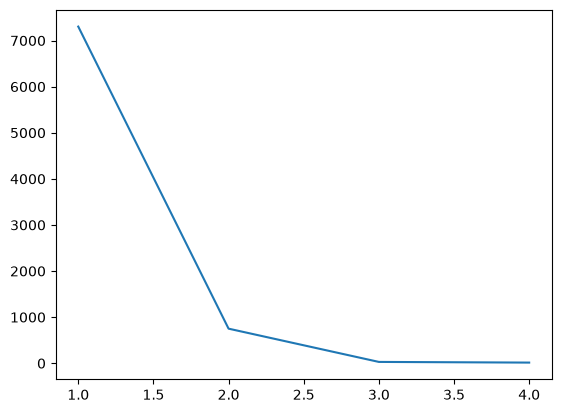

In [11]:
import matplotlib.pyplot as plt
plt.plot(range(1, 5), wcss)

# Elbow Method

## 1. What is it?
The **Elbow Method** is a heuristic used to find the **optimal number of clusters (K)** in clustering algorithms, most commonly **K-Means**.

You run K-Means for a range of K values (e.g., 1 to 10), measure how "tight" the clusters are for each, and plot the result. The point where the curve bends like an elbow is a good choice for K.

---

## 2. Intuition
- More clusters → points are closer to their centroids → error always decreases.
- But after a certain K, adding more clusters gives **diminishing returns**.
- The "elbow" is where the improvement drops sharply, so extra clusters are no longer worth the added complexity.

> Think of it like adding more workers to a job: the first few help a lot, but after a point each extra worker adds little.

---

## 3. Key Metric: WCSS (Inertia)

**WCSS** = Within-Cluster Sum of Squares

$$
WCSS = \sum_{k=1}^{K} \sum_{x_i \in C_k} \lVert x_i - \mu_k \rVert^2
$$

Where:
- $K$ = number of clusters
- $C_k$ = the k-th cluster
- $\mu_k$ = centroid of cluster $C_k$
- $x_i$ = a data point in the cluster

**Lower WCSS = tighter, more compact clusters.**

---

## 4. Steps
1. Choose a range of K values (e.g., 1 to 10).
2. For each K, run K-Means.
3. Compute WCSS (inertia) for each K.
4. Plot **K (x-axis)** vs **WCSS (y-axis)**.
5. Find the **elbow point**, where the curve flattens.
6. Choose that K.

---

## 5. Visual Idea

```
WCSS
 |
 |*
 |  *
 |    *
 |      *  <-- Elbow (K = 4)
 |         *  *  *  *
 +----------------------- K
   1  2  3  4  5  6  7
```

- Steep drop before the elbow
- Gentle slope after the elbow

---

## 6. Python Example

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Generate sample data with 4 true clusters
X, _ = make_blobs(n_samples=500, centers=4, random_state=42)

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)   # inertia_ = WCSS

plt.plot(K_range, wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()
```

**Expected result:** a clear elbow at **K = 4**.

---

## 7. Advantages
- Simple and easy to understand
- Easy to implement (`inertia_` in scikit-learn)
- Works well when clusters are well separated

## 8. Limitations
- The elbow is often **ambiguous** or not visible on real-world data
- Subjective: different people may pick different K
- Assumes K-Means style (spherical, similar-sized) clusters
- WCSS always decreases, so K = N (every point its own cluster) gives WCSS = 0
- Not reliable for clusters with varying density or non-convex shapes

---

## 9. Alternatives / Complements

| Method | Idea |
|---|---|
| **Silhouette Score** | Measures how well each point fits its own cluster vs. neighbors (range -1 to 1, higher is better) |
| **Gap Statistic** | Compares WCSS to that expected under a random reference distribution |
| **Davies-Bouldin Index** | Lower value = better separation |
| **Calinski-Harabasz Index** | Higher value = better-defined clusters |
| **KneeLocator (kneed library)** | Automatically detects the elbow point |

**Automatic elbow detection:**
```python
from kneed import KneeLocator

kl = KneeLocator(K_range, wcss, curve='convex', direction='decreasing')
print("Optimal K:", kl.elbow)
```

---

## 10. Common Pitfalls
- Forgetting to **scale features** (use `StandardScaler`) since K-Means is distance-based
- Trusting the elbow blindly; always cross-check with Silhouette Score or domain knowledge
- Using a single random initialization; set `n_init` higher or use `k-means++`

---

## 11. Quick Revision Points
- **Purpose:** find the best K for K-Means
- **Metric:** WCSS / inertia
- **Plot:** K vs WCSS
- **Pick:** the point where the curve bends (elbow)
- **Weakness:** subjective, not always clear
- **Pair with:** Silhouette Score for confirmation

---

## 12. Likely Exam / Interview Questions
1. **What does the elbow represent?**
   The point after which adding clusters gives only marginal reduction in WCSS.
2. **Why does WCSS always decrease as K increases?**
   More centroids means points are closer to their nearest centroid.
3. **What if there's no clear elbow?**
   Use Silhouette Score, Gap Statistic, or domain knowledge.
4. **Why scale data before the Elbow Method?**
   K-Means uses Euclidean distance, so large-scale features dominate.

---

Want me to make the next note on **Silhouette Score**, **K-Means**, or **Gap Statistic** in the same format?

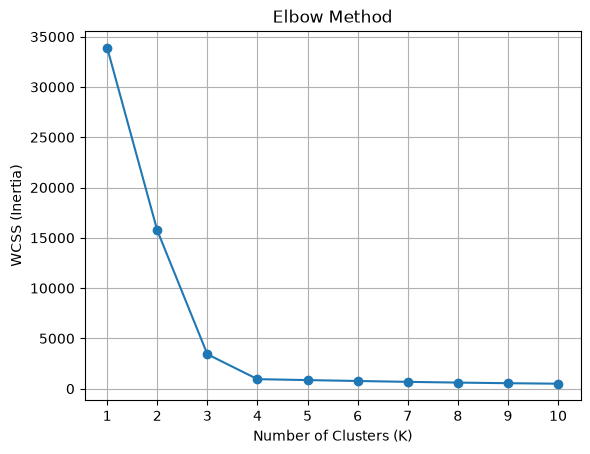

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs

# Generate sample data with 4 true clusters
X, _ = make_blobs(n_samples=500, centers=4, random_state=42)

wcss = []
K_range = range(1, 11)

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)   # inertia_ = WCSS

plt.plot(K_range, wcss, marker='o')
plt.title('Elbow Method')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS (Inertia)')
plt.xticks(K_range)
plt.grid(True)
plt.show()

# Silhouette Score

## 1. What is it?
The **Silhouette Score** is a metric that measures **how well each data point fits its own cluster compared to the other clusters**. It is used to evaluate clustering quality and to choose the **optimal number of clusters (K)**.

Unlike the Elbow Method (which is visual and subjective), it gives a **single number between -1 and 1**.

---

## 2. Intuition
For every point, ask two questions:
1. How close is it to the other points **in its own cluster**? (cohesion)
2. How far is it from the points in the **nearest other cluster**? (separation)

A good clustering has **high cohesion** (points close to their own cluster) and **high separation** (far from other clusters).

> Think of students sitting in a classroom: a well-clustered student sits close to their own group and far from other groups. A badly clustered student sits closer to another group than their own.

---

## 3. Formula

For a single data point $i$:

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}
$$

Where:
- $a(i)$ = **average distance** from point $i$ to all other points in **its own cluster** (cohesion)
- $b(i)$ = **average distance** from point $i$ to all points in the **nearest neighboring cluster** (separation)

**Overall Silhouette Score** = the mean of $s(i)$ over all points.

**Special case:** if a cluster has only one point, $s(i) = 0$.

---

## 4. Interpreting the Value

| Value of $s(i)$ | Meaning |
|---|---|
| **Close to +1** | Point is well matched to its own cluster and far from others |
| **Close to 0** | Point lies on or near the boundary between two clusters |
| **Negative** | Point is probably assigned to the wrong cluster |

**Rough guide for the average score:**

| Average Score | Interpretation |
|---|---|
| 0.71 to 1.00 | Strong structure |
| 0.51 to 0.70 | Reasonable structure |
| 0.26 to 0.50 | Weak structure, may be artificial |
| Below 0.25 | No substantial structure |

*(These ranges are a common rule of thumb, not a strict standard.)*

---

## 5. Steps to Choose K
1. Choose a range of K values (**start from 2**, since silhouette needs at least 2 clusters).
2. For each K, run K-Means.
3. Compute the average Silhouette Score.
4. Plot **K vs Silhouette Score**.
5. Choose the K with the **highest score**.

---

## 6. Visual Idea

```
Silhouette
Score
 |
 |      *  <-- Best K = 4 (highest peak)
 |    *   *
 |  *       *
 |            *  *
 +----------------------- K
   2  3  4  5  6  7
```

Unlike the elbow, you look for the **peak**, not a bend.

---

## 7. Python Example

```python
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
from sklearn.metrics import silhouette_score

# Sample data with 4 true clusters
X, _ = make_blobs(n_samples=500, centers=4, random_state=42)

scores = []
K_range = range(2, 11)   # silhouette needs K >= 2

for k in K_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    labels = kmeans.fit_predict(X)
    scores.append(silhouette_score(X, labels))

plt.plot(K_range, scores, marker='o')
plt.title('Silhouette Score vs K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Average Silhouette Score')
plt.xticks(K_range)
plt.grid(True)
plt.show()

best_k = K_range[int(np.argmax(scores))]
print("Best K:", best_k)
```

**Per-point scores (for silhouette plots):**
```python
from sklearn.metrics import silhouette_samples

sample_scores = silhouette_samples(X, labels)   # s(i) for every point
```

---

## 8. Silhouette Plot (Detailed Diagnosis)
A silhouette plot shows each cluster's points as horizontal bars, sorted by score.

What to check:
- **Bar width (score):** should be well above 0 for all clusters
- **Bars crossing the average line:** most clusters should extend past the average score
- **Cluster thickness:** clusters of very different sizes may indicate a poor K
- **Negative bars:** misassigned points

---

## 9. Advantages
- Gives a **single, interpretable score** (-1 to 1)
- Less subjective than the Elbow Method
- Works for **any clustering algorithm**, not just K-Means
- Provides **per-point** insight, not just global insight
- Does **not need ground-truth labels** (unsupervised metric)

## 10. Limitations
- **Computationally expensive:** needs pairwise distances, roughly $O(n^2)$, slow on large datasets
- Favors **convex, well-separated, spherical** clusters
- Can give **misleading scores for density-based clusters** (e.g., DBSCAN, moon-shaped or ring-shaped data)
- Sensitive to the **distance metric** and **feature scaling**
- Needs at least 2 clusters and fewer clusters than samples

**Tip for large data:** use `sample_size` in `silhouette_score` to compute on a subset.

---

## 11. Elbow Method vs Silhouette Score

| Aspect | Elbow Method | Silhouette Score |
|---|---|---|
| Metric | WCSS (inertia) | Cohesion vs separation |
| Output | Curve with a bend | Score in [-1, 1] |
| Decision | Visual, subjective | Pick the maximum |
| Considers separation? | No, only compactness | Yes |
| Speed | Fast | Slower ($O(n^2)$) |
| Works with any algorithm? | Mainly K-Means | Yes |
| Starts at K = | 1 | 2 |

---

## 12. Common Pitfalls
- Trying to compute it with **K = 1** (raises an error)
- Forgetting to **scale features** with `StandardScaler`
- Picking K only from the average score; also check the **silhouette plot**
- Using it to compare clusterings on **non-convex data**
- Comparing scores across **different datasets** (score is only meaningful within one dataset)

---

## 13. Quick Revision Points
- **Purpose:** evaluate clustering quality and pick K
- **Formula:** $s = \dfrac{b - a}{\max(a, b)}$
- **a** = intra-cluster distance, **b** = nearest-cluster distance
- **Range:** -1 to +1, higher is better
- **Choose:** K with the **highest** average score
- **Weakness:** slow and biased toward spherical clusters
- **Pair with:** Elbow Method for confirmation

---

## 14. Likely Exam / Interview Questions
1. **What does a silhouette score of 0 mean?**
   The point lies on the boundary between two clusters.
2. **What does a negative score mean?**
   The point is likely assigned to the wrong cluster.
3. **Why can't we compute it for K = 1?**
   There is no "nearest other cluster" to compute $b(i)$.
4. **Why is it better than the Elbow Method?**
   It accounts for both cohesion and separation, and gives a clear maximum instead of a subjective bend.
5. **When does it fail?**
   With non-convex or density-based clusters (e.g., DBSCAN results on moon-shaped data).

---

Want the next note on **K-Means**, **Gap Statistic**, or **DBSCAN**?

In [13]:
import pandas as pd
import numpy as np


data = pd.read_csv(r"D:\SevenMentor\ML\workspace\Dhanaji_ml\dataset\loan_approval_dataset.csv")

In [14]:
data

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [15]:
cot = []
cat = []

for i in data.columns:
    if data[i].dtype == "str":
        cot.append(i)
    else:
        cat.append(i)

In [16]:
cot

[' education', ' self_employed', ' loan_status']

In [17]:
df = data[cat[1:]]

In [18]:
df

,no_of_dependents,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value
0,2,9600000,29900000,12,778,2400000,17600000,22700000,8000000
1,0,4100000,12200000,8,417,2700000,2200000,8800000,3300000
2,3,9100000,29700000,20,506,7100000,4500000,33300000,12800000
3,3,8200000,30700000,8,467,18200000,3300000,23300000,7900000
4,5,9800000,24200000,20,382,12400000,8200000,29400000,5000000
...,...,...,...,...,...,...,...,...,...
4264,5,1000000,2300000,12,317,2800000,500000,3300000,800000
4265,0,3300000,11300000,20,559,4200000,2900000,11000000,1900000
4266,2,6500000,23900000,18,457,1200000,12400000,18100000,7300000
4267,1,4100000,12800000,8,780,8200000,700000,14100000,5800000


In [19]:
# perform stander scaler

# from sklearn.preprocessing import 
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

sd = StandardScaler()

In [20]:
df_sc = sd.fit_transform(df)

In [35]:
df_sc[[0]]

array([[-0.2941017 ,  1.61797904,  1.63305171,  0.19261651,  1.03279241,
        -0.78005754,  2.877289  ,  0.83202837,  0.93030441]])

In [22]:
df_sc.shape

(4269, 9)

In [23]:
# now perform k-mean

In [24]:
from sklearn.cluster import KMeans



In [25]:
kmeans = KMeans(n_clusters=2, 
        random_state=42
)

In [26]:
labels = kmeans.fit(df_sc)

In [27]:
da = labels.labels_

In [28]:
new_da = pd.DataFrame(da)

In [29]:
new_da

,0
0,1
1,0
2,1
3,1
4,1
...,...
4264,0
4265,0
4266,1
4267,0


In [30]:
print("Centroids:\n", kmeans.cluster_centers_)
print("Inertia:", kmeans.inertia_)

Centroids:
 [[-0.02388046 -0.8421776  -0.79427813 -0.00435573  0.02190999 -0.57089357
  -0.59082182 -0.79756274 -0.74367666]
 [ 0.02432081  0.85770711  0.8089244   0.00443605 -0.022314    0.58142068
   0.6017164   0.81226957  0.75738985]]
Inertia: 24484.936393174477


In [31]:
wacs = []

for i in range(1, df_sc.shape[1]+1):
    kms = KMeans(
        n_clusters=i,
        random_state=0
    )
    kms.fit(df_sc)
    print(kms.inertia_)
    wacs.append(kms.inertia_)

38421.0
24485.1507806777
21588.08081474241
20300.602423954537
19146.577696511562
17943.512315156084
17209.3801568063
16511.230208840137
15851.80712550052


In [32]:
wacs

[38421.0,
 24485.1507806777,
 21588.08081474241,
 20300.602423954537,
 19146.577696511562,
 17943.512315156084,
 17209.3801568063,
 16511.230208840137,
 15851.80712550052]

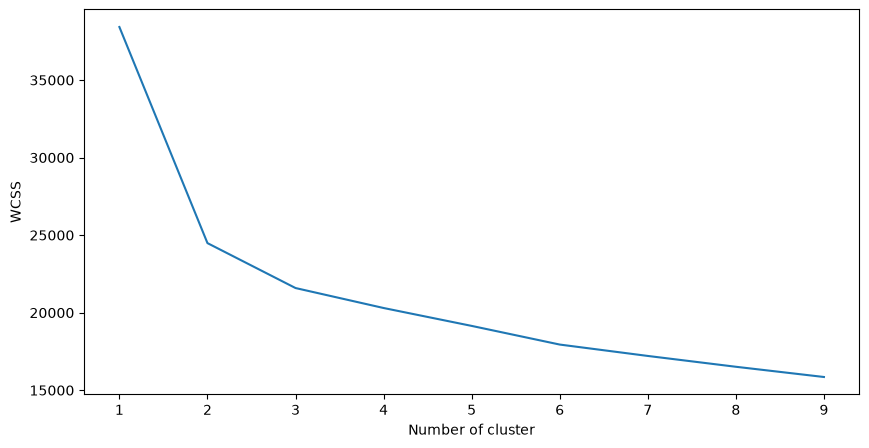

In [34]:
plt.figure(figsize = (10,5))
plt.plot([1,2,3,4,5,6,7,8,9],wacs)
plt.xlabel('Number of cluster')
plt.ylabel('WCSS')
plt.show()

In [38]:
kms = KMeans(
    n_clusters=2,
    random_state=0)
kms.fit(df_sc)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 9)","[[

In [40]:
kms.predict(df_sc[[0]])

array([1], dtype=int32)

In [41]:
kms.predict(df_sc[[1]])

array([0], dtype=int32)

In [58]:
result = []
for i in range(10):
    result.append(kms.predict(df_sc[[i]]))

In [80]:
kms.labels_

array([1, 0, 1, ..., 1, 0, 1], shape=(4269,), dtype=int32)

In [59]:
data[" loan_status"].head(10)

0     Approved
1     Rejected
2     Rejected
3     Rejected
4     Rejected
5     Rejected
6     Approved
7     Rejected
8     Approved
9     Rejected
Name:  loan_status, dtype: str

In [60]:
k = pd.DataFrame()

In [61]:
k["loan_status"] = data[" loan_status"].head(10)

In [62]:
k["result"] = result

In [63]:
k

,loan_status,result
0,Approved,[1]
1,Rejected,[0]
2,Rejected,[1]
3,Rejected,[1]
4,Rejected,[1]
5,Rejected,[1]
6,Approved,[1]
7,Rejected,[1]
8,Approved,[0]
9,Rejected,[0]
